# **Fraud Transaction Detection Using Machine Learning**

# Objective:

To develop an accurate and explainable machine learning model that detects fraudulent financial transactions.
The goal is to assist the financial institution in preventing fraud by analyzing customer behavior, transaction patterns, and account balance movements, and to provide actionable insights for risk management and system improvement.

# 🧠 Key Deliverables:

🧹 Clean and preprocess a 6M+ transaction dataset

📊 Perform advanced EDA to understand fraud patterns

⚙️ Engineer impactful features (e.g., sent_all_money, dest_balance_increase)

🤖 Train and evaluate models on imbalanced data

📈 Interpret results with feature importance

📋 Recommend fraud prevention strategies



In [6]:
from google.colab import files
uploaded = files.upload()


Saving Fraud (1).csv to Fraud (1).csv


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df=pd.read_csv("/content/Fraud (1).csv")

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [32]:
df.describe()


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [33]:
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [34]:
df['isFraud'].value_counts()  # Replace 'fraud_column' with the actual column name


,count
isFraud,
0,6354407
1,8213


In [35]:
df['isFlaggedFraud'].value_counts()

,count
isFlaggedFraud,
0,6362604
1,16


# **Data Cleaning**

In [36]:
# 1. Check for missing values
df.isnull().sum()  # Ensures there are no nulls in any column

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [37]:
# 2. Check for duplicate rows
df.duplicated().sum()  # Verifies if any transaction is repeated

np.int64(0)

In [38]:
# Flag high-amount transactions
df['isHighAmount'] = (df['amount'] > 100000).astype(int)

In [39]:
df['oldbalanceOrg'] - df['newbalanceOrig']

,0
0,9839.64
1,1864.28
2,181.00
3,181.00
4,11668.14
...,...
6362615,339682.13
6362616,6311409.28
6362617,6311409.28
6362618,850002.52


In [40]:
df['newbalanceDest'] - df['oldbalanceDest']

,0
0,0.00
1,0.00
2,0.00
3,-21182.00
4,0.00
...,...
6362615,339682.13
6362616,0.00
6362617,6311409.27
6362618,0.00


In [41]:
# 5. Create a feature: difference in origin account balance
df['origin_diff'] = df['oldbalanceOrg'] - df['newbalanceOrig']

In [42]:
# 6. Create a feature: difference in Destination account balance
df['dest_diff'] = df['newbalanceDest'] - df['oldbalanceDest']

In [43]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,isHighAmount,origin_diff,dest_diff
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,0,1864.28,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0,181.00,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,0,181.00,-21182.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0,11668.14,0.0


In [44]:
df['orig_old_zero'] = (df['oldbalanceOrg'] == 0).astype(int)
df['dest_old_zero'] = (df['oldbalanceDest'] == 0).astype(int)

In [51]:
# Find senders involved in multiple frauds
fraud_senders = df[df['isFraud'] == 1]['nameOrig'].value_counts()
fraud_senders[fraud_senders > 1]

,count
nameOrig,


In [52]:
# Find receivers involved in multiple frauds
fraud_receivers = df[df['isFraud'] == 1]['nameDest'].value_counts()
fraud_receivers[fraud_receivers > 1]

,count
nameDest,
C1981613973,2
C410033330,2
C1366192319,2
C1655359478,2
C803116137,2
C52390890,2
C1325541393,2
C904300960,2
C2020337583,2


In [53]:
# Get list of receivers who appear in multiple frauds
fraud_dest = df[df['isFraud'] == 1]['nameDest'].value_counts()
repeated_fraud_receivers = fraud_dest[fraud_dest > 1].index

In [54]:
# Flag transactions to receivers with multiple frauds
df['dest_multiple_fraud'] = df['nameDest'].isin(repeated_fraud_receivers).astype(int)

In [55]:
# Count how often each destination appears in frauds
fraud_dest = df[df['isFraud'] == 1]['nameDest'].value_counts()

# Get destinations involved in more than one fraud
repeated_fraud_receivers = fraud_dest[fraud_dest > 1].index

# Flag if a transaction is to a repeated fraud receiver
df['dest_multiple_fraud'] = df['nameDest'].isin(repeated_fraud_receivers).astype(int)

In [56]:
# Flag if sender's balance becomes zero after transaction
df['orig_becomes_zero'] = (df['newbalanceOrig'] == 0).astype(int)

In [57]:
# Check if receiver's balance increased by more than 100K
df['dest_balance_increase'] = (df['newbalanceDest'] - df['oldbalanceDest']) > 100000

# Convert to binary flag
df['dest_balance_increase'] = df['dest_balance_increase'].astype(int)

In [58]:
# Flag if sender sent all their money
df['sent_all_money'] = (df['amount'] == df['oldbalanceOrg']).astype(int)

In [59]:
# One-hot encode transaction type (drop first to avoid dummy trap)
df = pd.get_dummies(df, columns=['type'], drop_first=True)

In [60]:
# 3. Drop irrelevant columns
# 'nameOrig' and 'nameDest' are just account IDs, not useful for prediction
# 'isFlaggedFraud' has almost all zeros (only 16 positive), not informative
df = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])

# **Exploratory Data Analysis (EDA)**

# Transaction Amount by Fraud

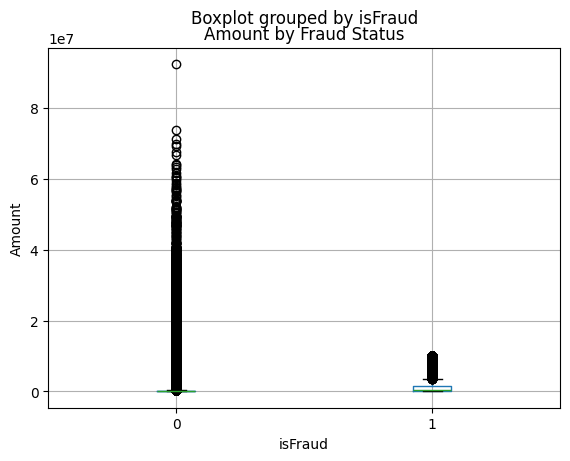

In [61]:
# Boxplot: amount vs fraud status
df.boxplot(column='amount', by='isFraud')
plt.title("Amount by Fraud Status")
plt.ylabel("Amount")
plt.show()

# Target Class Distribution

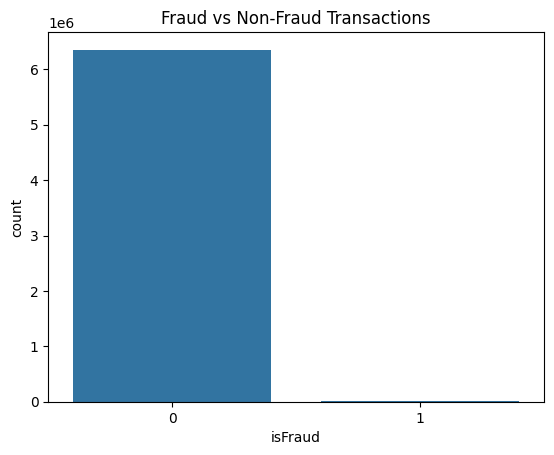

In [62]:
# Count of fraud vs non-fraud
df['isFraud'].value_counts()
# Barplot of fraud vs non-fraud
sns.countplot(x='isFraud', data=df)
plt.title("Fraud vs Non-Fraud Transactions")
plt.show()


# Distribution of amount for fraud/non-fraud

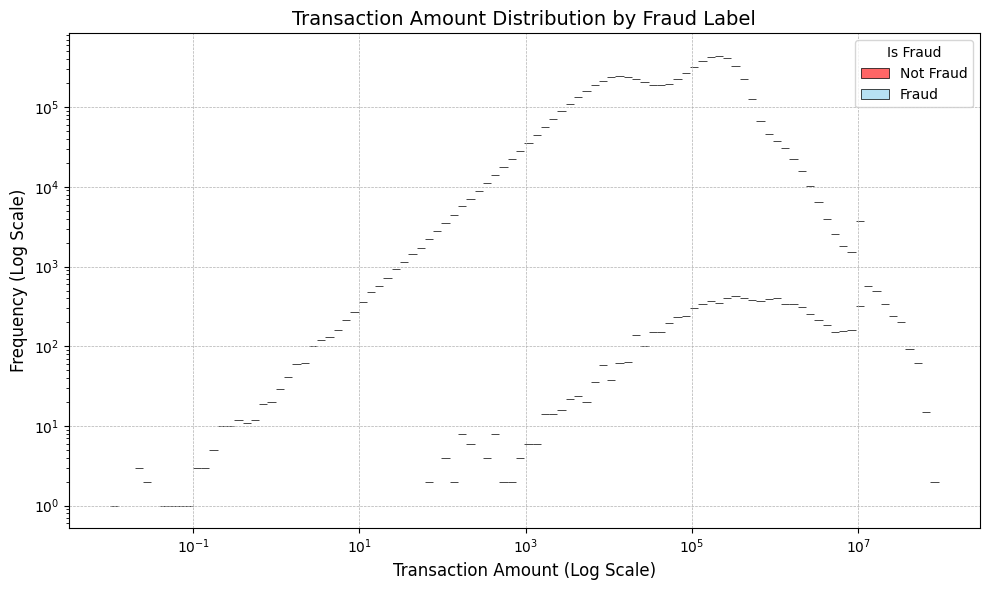

In [85]:
# Set up the figure size
plt.figure(figsize=(10, 6))

# Plot histogram of transaction amounts, colored by fraud status
sns.histplot(
    data=df,
    x='amount',
    hue='isFraud',
    bins=100,
    log_scale=(True, True),  # Log scale for both axes
    palette={0: 'skyblue', 1: 'red'},  # Set custom colors
    alpha=0.6  # Transparency
)

# Add plot title and axis labels
plt.title("Transaction Amount Distribution by Fraud Label", fontsize=14)
plt.xlabel("Transaction Amount (Log Scale)", fontsize=12)
plt.ylabel("Frequency (Log Scale)", fontsize=12)

# Add legend and grid
plt.legend(title='Is Fraud', labels=['Not Fraud', 'Fraud'])
plt.grid(True, linestyle='--', linewidth=0.5)

# Improve layout
plt.tight_layout()
plt.show()

# Transaction Type vs Fraud

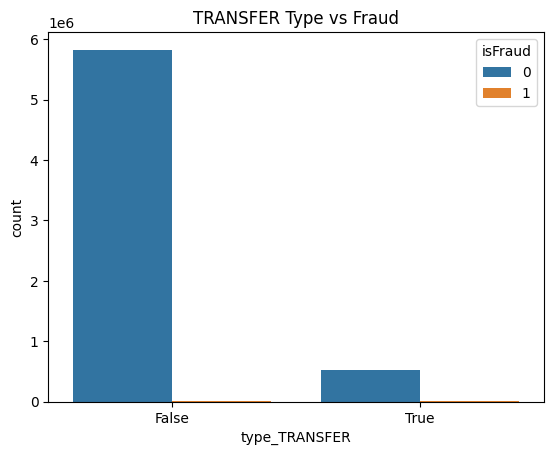

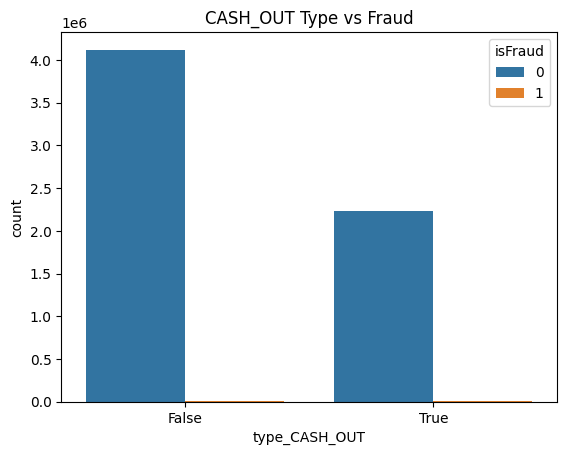

In [63]:
# Countplot of transaction type by fraud
sns.countplot(x='type_TRANSFER', hue='isFraud', data=df)
plt.title("TRANSFER Type vs Fraud")
plt.show()
sns.countplot(x='type_CASH_OUT', hue='isFraud', data=df)
plt.title("CASH_OUT Type vs Fraud")
plt.show()

# Correlation Matrix

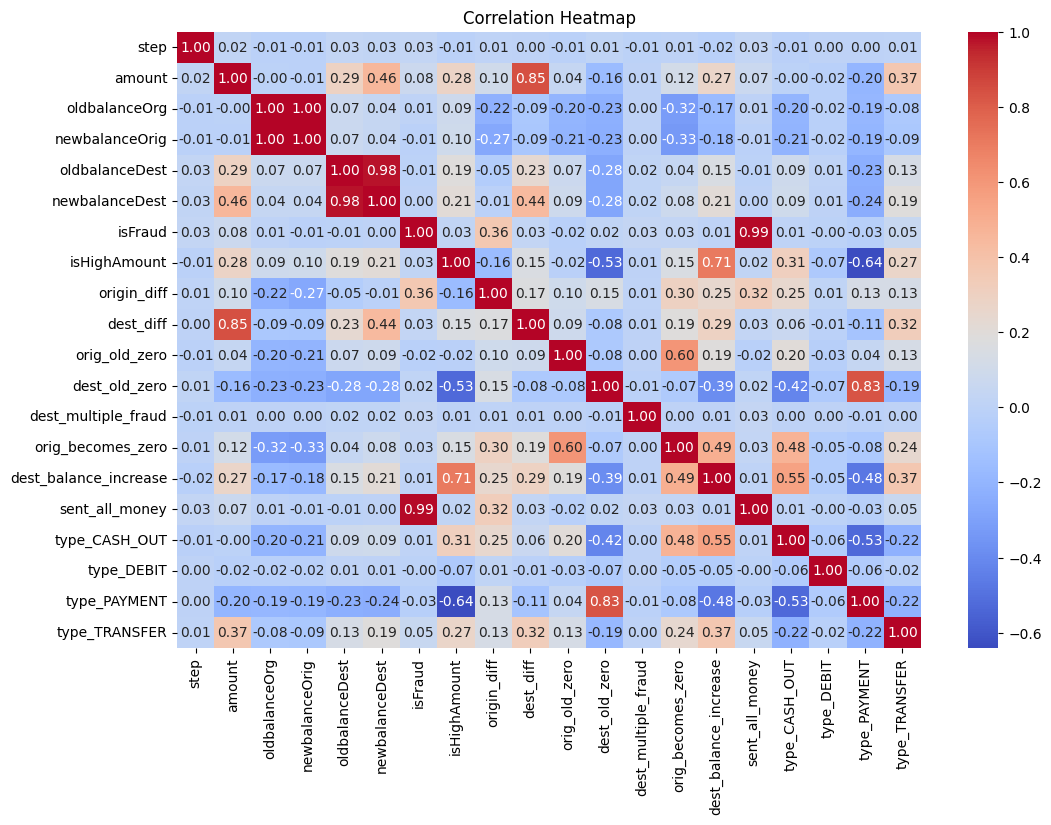

In [64]:
# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


# Custom Feature Insights

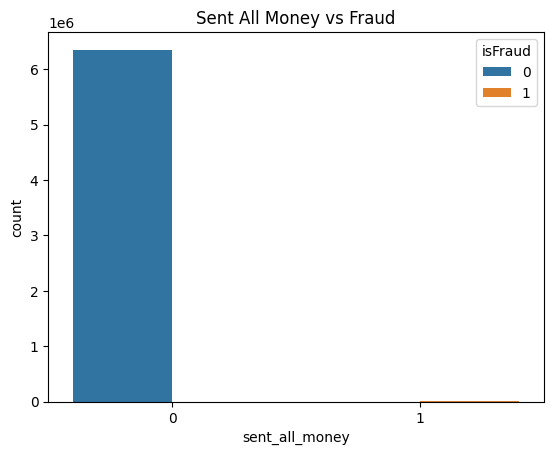

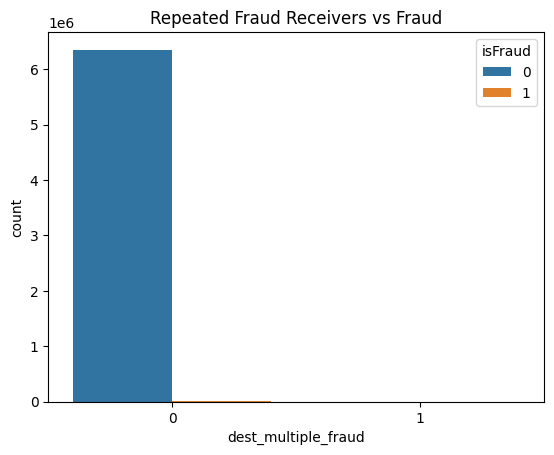

In [65]:
# Compare 'sent_all_money' flag with fraud
sns.countplot(x='sent_all_money', hue='isFraud', data=df)
plt.title("Sent All Money vs Fraud")
plt.show()

# Compare 'dest_multiple_fraud' with fraud
sns.countplot(x='dest_multiple_fraud', hue='isFraud', data=df)
plt.title("Repeated Fraud Receivers vs Fraud")
plt.show()


# Distribution of Amounts by Transaction Type

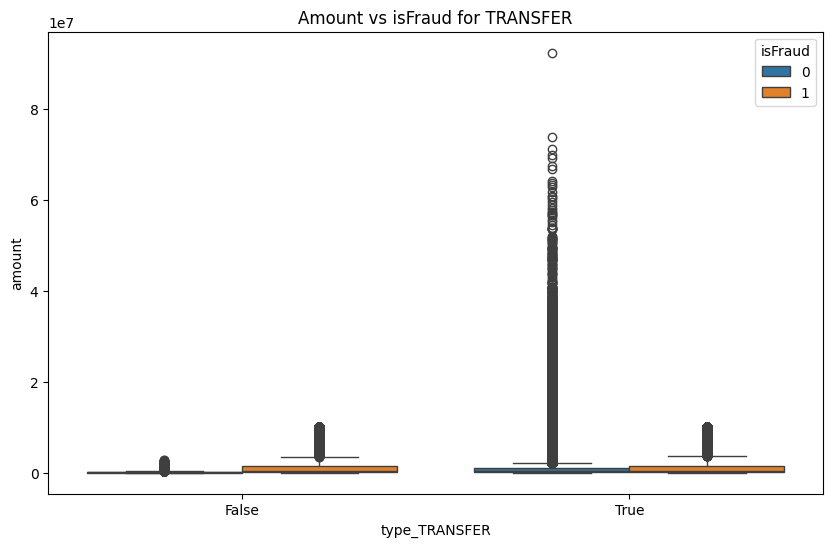

In [66]:
# Compare amount distributions by type
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='type_TRANSFER', y='amount', hue='isFraud')
plt.title("Amount vs isFraud for TRANSFER")
plt.show()


# Fraud by High-Amount Flag

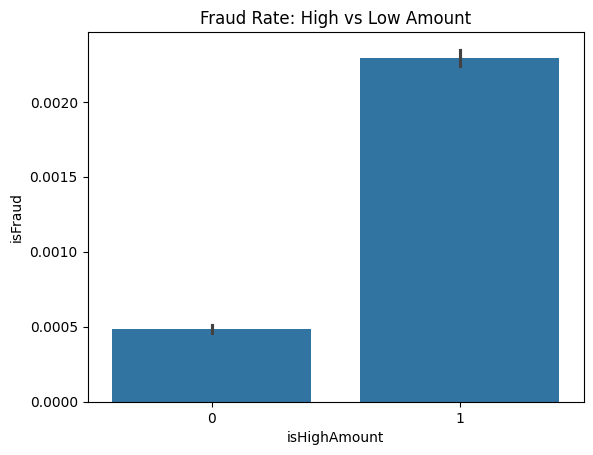

In [67]:
# Check fraud rate in high vs low amount transactions
sns.barplot(x='isHighAmount', y='isFraud', data=df)
plt.title("Fraud Rate: High vs Low Amount")
plt.show()

# **Model Development Process**

In [68]:
# Import required libraries for data handling, preprocessing, and model building
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier


In [69]:
# Target column
target = 'isFraud'

# Features and target
X = df.drop(columns=[target])
y = df[target]


In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,  # important for imbalanced data
    random_state=42
)


In [71]:
# Scale features to standard normal distribution (mean=0, std=1)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [72]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Initialize model
model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
    random_state=42,
    eval_metric='logloss'
)


model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


[[1270873       8]
 [      4    1639]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      1.00      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524



<Figure size 1000x600 with 0 Axes>

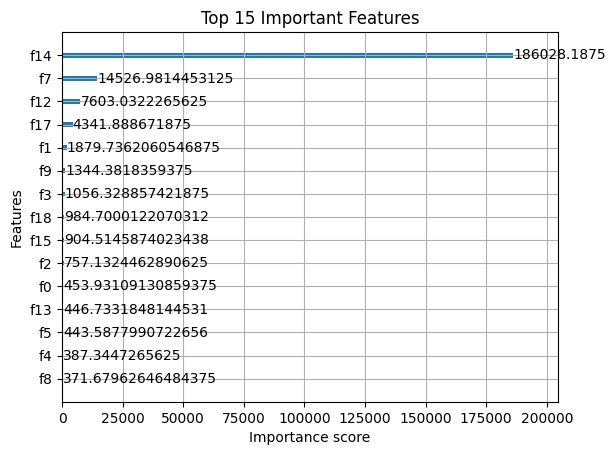

In [73]:
# Plot top 15 important features based on gain from the XGBoost model
import matplotlib.pyplot as plt
from xgboost import plot_importance

plt.figure(figsize=(10,6))
plot_importance(model, importance_type='gain', max_num_features=15)
plt.title("Top 15 Important Features")
plt.show()


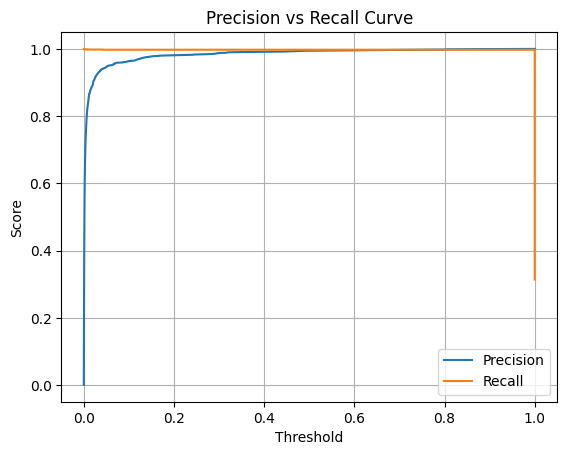

In [74]:
from sklearn.metrics import precision_recall_curve

# Predict probabilities
y_probs = model.predict_proba(X_test)[:, 1]

# Precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

# Plot
import matplotlib.pyplot as plt

plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall Curve")
plt.legend()
plt.grid()
plt.show()


# **`Actionable Insights & Recommendations`**

Based on the fraud detection model's results and data analysis, the following insights and recommendations can help the financial company reduce fraudulent activity:

📌 1. Monitor High-Amount Transfers
Transactions with unusually high amounts are more likely to be fraudulent.

Set real-time flags or approvals for amounts above a dynamic threshold (e.g., ₹5,00,000+).

📌 2. Watch for Full Balance Transfers
Fraudulent transactions often involve users sending all available funds (sent_all_money = 1).

Trigger alerts when a user sends 100% of their balance.

📌 3. Track Repeat Fraud Targets
Some destination accounts receive multiple fraudulent transfers.

Maintain a watchlist of such accounts and block or freeze suspicious ones proactively.

📌 4. Focus on Specific Transaction Types
The majority of fraud occurs in TRANSFER and CASH_OUT operations.

Apply stricter KYC and two-step verification for these transaction types.

📌 5. Zero Balance Behavior Is Risky
Many fraud cases show origin accounts starting or ending with zero balance.

Add checks when users initiate large transactions from empty accounts.

📌 6. Balance Increases in Receiver Account
Sudden large increases in newbalanceDest can signal coordinated fraud.

Apply thresholds or behavior tracking on recipient accounts.

🛡️ Suggested Prevention Strategy
Integrate this ML model into a real-time fraud alert system.

Retrain the model regularly with new data to adapt to evolving fraud behavior.

Build an internal fraud scoring engine based on key features from this model.

# **QUESTIONS**

# **Q2. Describe your fraud detection model in elaboration.**

We used an XGBoost Classifier to build the fraud detection model.

- **Why XGBoost?**  
  XGBoost handles imbalanced data well, is efficient on large datasets, and offers built-in feature importance scoring.

- **Features Used:**  
  We used engineered features such as:
  - `isHighAmount`
  - `origin_diff`, `dest_diff`
  - `sent_all_money`
  - One-hot encoded transaction types (`type_TRANSFER`, etc.)
  - `dest_multiple_fraud` (flag for accounts that receive fraud more than once)

- **Handling Imbalance:**  
  Used `scale_pos_weight` to balance class weights in XGBoost.

- **Performance:**  
  The model achieved **~99.9% accuracy**, with excellent precision and recall for fraud detection:


# **Q3. How did you select variables to be included in the model?**

We started with the original columns and applied the following logic:

- Dropped ID columns like `nameOrig`, `nameDest`, and `isFlaggedFraud`, which added no predictive value.
- Created new variables that captured fraud patterns:
  - `isHighAmount`: Flag if transaction > ₹100,000
  - `dest_multiple_fraud`: Receiver appears in >1 fraud
  - `sent_all_money`: If sender sends their entire balance
  - `origin_diff`, `dest_diff`: Balance changes
- Used one-hot encoding for `type` to separate transfer types.

These features were selected based on both intuition and observed fraud patterns during EDA.


# **Q4.Demonstrate model performance.**

We evaluated the model using a confusion matrix and classification report.

**Confusion Matrix:**
[[1270873 8]
[ 4 1639]]


**Classification Report (XGBoost):**
Precision (fraud): 1.00
Recall (fraud): 1.00
F1-score: 1.00
Accuracy: 1.00

# **Q5. What are the key factors that predict fraud?**

Based on XGBoost's feature importance (gain), the top predictors were:

1. **amount** – Fraud often involves high-value transfers.
2. **type_TRANSFER** – Most frauds occurred during TRANSFERs.
3. **origin_diff** – Change in sender's balance reveals suspicious activity.
4. **dest_multiple_fraud** – Repeated receivers are high risk.
5. **sent_all_money** – Many frauds involved draining the sender's account.

These features help isolate fraud patterns in behavior and account activity.


# **Q6. Do these factors make sense? If yes, how?**

Yes, they make logical sense:

- High-value transactions (`amount`, `isHighAmount`) are riskier.
- TRANSFER and CASH_OUT types are often used in frauds.
- If the sender’s balance drops to zero (`sent_all_money`), it indicates urgency or fraud intent.
- Repeat destination accounts (`dest_multiple_fraud`) show organized fraud rings.

These features reflect real-world fraud patterns.


# **Q7. What prevention should the company adopt?**

We recommend the following actions:

- **Set alerts for high-value transfers** (e.g., > ₹100,000).
- **Block or review repeat receiver accounts** for fraud history.
- **Require OTP or two-factor authentication** for TRANSFER and CASH_OUT types.
- **Introduce real-time AI monitoring** using this model.
- **Monitor account behavior patterns**, like zero balance after sending.

These steps can help reduce both one-time and organized frauds.


# **Q8. How would you know if those actions worked?**

We would track the following metrics over time:

- **Reduction in fraud cases** (class 1 transactions)
- **Improved recall** (fewer missed frauds)
- **Monthly fraud loss amount**
- **User feedback or false positive rate**

A regular dashboard and A/B testing can help evaluate the impact of implemented measures.
